In [60]:
"""
Programa para implementar el algoritmo de descenso de gradiente con
retropropagación
"""
%config InlineBackend.figure_format = 'retina'

import random
import numpy as np
import matplotlib.pyplot as plt
import copy

In [61]:
class Network(object):

    def __init__(self, sizes):
        """The list ``sizes`` contains the number of neurons in the
        respective layers of the network.  For example, if the list
        was [2, 3, 1] then it would be a three-layer network, with the
        first layer containing 2 neurons, the second layer 3 neurons,
        and the third layer 1 neuron.  The biases and weights for the
        network are initialized randomly, using a Gaussian
        distribution with mean 0, and variance 1.  Note that the first
        layer is assumed to be an input layer, and by convention we
        won't set any biases for those neurons, since biases are only
        ever used in computing the outputs from later layers."""
        self.num_layers = len(sizes)
        self.sizes = sizes
        self.biases = [np.random.randn(y, 1) for y in sizes[1:]]
        self.weights = [np.random.randn(y, x)
                        for x, y in zip(sizes[:-1], sizes[1:])]
        
        # MOMENTUM Initialize velocity buffers for momentum (same shape as weights/biases)
        self.v_biases = [np.zeros(b.shape) for b in self.biases]
        self.v_weights = [np.zeros(w.shape) for w in self.weights]
   
        self.test_results = []
        self.loss = 0
        self.fallos = 0

    def feedforward(self, a):
        act = a[0:0-1].T
        act = np.array([[a[0],a[1]]]).T
        """Return the output of the network if ``a`` is input."""
        for b, w in zip(self.biases, self.weights):
            act = sigmoid(np.dot(w, act)+b)
        return (act[0][0]>0.5)

    def SGD(self, training_data, epochs, mini_batch_size, lrate, mu=0.9, test_data=[]):
        """
        Added 'mu' parameter for momentum (default 0.9).
        """
        if (len(test_data) > 0): 
            n_test = len(test_data)
        n = len(training_data)
        for j in range(epochs):
            random.shuffle(training_data)
            mini_batches = [
                training_data[k:k+mini_batch_size]
                for k in range(0, n, mini_batch_size)]
            for mini_batch in mini_batches:
                # Pass mu to the update function
                self.update_mini_batch(mini_batch, lrate, mu)          
            
            if len(test_data):
                tasafallos, self.test_results = self.evaluate(test_data)
                tasafallos /= len(test_data)
                print("Epoch {0} loss {1} Tasa fallos {2}".format(j, self.loss, tasafallos))
            else:
                print("Epoch {0} complete. loss {1}".format(j, self.loss))

    def update_mini_batch(self, mini_batch, lrate, mu):
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        epoch_loss = 0
        lbatch = len(mini_batch)    
        
        for k in range(lbatch):
            x = np.array([[mini_batch[k][0], mini_batch[k][1]]]).T
            y = mini_batch[k][2]
            delta_nabla_b, delta_nabla_w, loss = self.backprop(x, y)
            nabla_b = [nb + dnb for nb, dnb in zip(nabla_b, delta_nabla_b)]
            nabla_w = [nw + dnw for nw, dnw in zip(nabla_w, delta_nabla_w)]
            epoch_loss += loss

        # MOMENTUM Apply Momentum Update Rule:
        # 1. Update velocities: v = mu * v - (learning_rate/batch_size) * gradient
        self.v_weights = [mu * vw - (lrate/lbatch) * nw 
                          for vw, nw in zip(self.v_weights, nabla_w)]
        self.v_biases = [mu * vb - (lrate/lbatch) * nb 
                         for vb, nb in zip(self.v_biases, nabla_b)]
        
        # 2. Update weights and biases: theta = theta + v
        self.weights = [w + vw for w, vw in zip(self.weights, self.v_weights)]
        self.biases = [b + vb for b, vb in zip(self.biases, self.v_biases)]
        
        self.loss = epoch_loss / lbatch



    def backprop(self, x, y):
        """Return a tuple ``(nabla_b, nabla_w)`` representing the
        gradient for the loss function C_x.  ``nabla_b`` and
        ``nabla_w`` are layer-by-layer lists of numpy arrays, similar
        to ``self.biases`` and ``self.weights``."""
        nabla_b = [np.zeros(b.shape) for b in self.biases]
        nabla_w = [np.zeros(w.shape) for w in self.weights]
        # feedforward
        activation = x
        activations = [x] # list to store all the activations, layer by layer
        zs = [] # list to store all the z vectors, layer by layer
        for b, w in zip(self.biases, self.weights):
            z = np.dot(w, activation)+b
            zs.append(z)
            activation = sigmoid(z)
            activations.append(activation)
        # backward pass
        loss = (0.5)*(activations[-1]-y)**2
        delta = self.loss_derivative(activations[-1], y) * \
            sigmoid_prime(zs[-1])
        nabla_b[-1] = delta
        nabla_w[-1] = np.dot(delta, activations[-2].transpose())
        # Note that the variable l in the loop below is used a little
        # differently to the notation in Chapter 2 of the book.  Here,
        # l = 1 means the last layer of neurons, l = 2 is the
        # second-last layer, and so on.  It's a renumbering of the
        # scheme in the book, used here to take advantage of the fact
        # that Python can use negative indices in lists.
        for l in range(2, self.num_layers):
            z = zs[-l]
            sp = sigmoid_prime(z)
            delta = np.dot(self.weights[-l+1].transpose(), delta) * sp
            nabla_b[-l] = delta
            nabla_w[-l] = np.dot(delta, activations[-l-1].transpose())
        return (nabla_b, nabla_w, loss)

    def evaluate(self, test_data):
        """Return the number of test inputs for which the neural
        network outputs the correct result. Note that the neural
        network's output is assumed to be the index of whichever
        neuron in the final layer has the highest activation."""
        test_labels = [test_data[k][2] for k in range(len(test_data))]
        self.test_results = [self.feedforward(x) for x in test_data]
        self.fallos = np.sum(abs(np.array(test_labels)-np.array(self.test_results))) 
        return self.fallos, np.array(self.test_results)*1.0

    def loss_derivative(self, output_activations, y):
        """Return the vector of partial derivatives C_x for the output activations."""
        return (output_activations-y)

In [62]:
#### Miscellaneous functions
def sigmoid(z):
    """The sigmoid function."""
    return 1.0/(1.0+np.exp(-z))

def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))


# Crea un array de números aletorios con distribución normal de media cero y desviación estándar 1
def random_init(longitud):
    return (np.random.randn(longitud))

# Crea los datos de entrada. 
def crea_datos(numpuntos):
    inputs = [np.array(np.random.rand(numpuntos))]  # Fila 0, valores x
    inputs.append(np.random.rand(numpuntos))        # Fila 1, valores y   
    inputs.append(np.zeros(numpuntos))              # Fila 2, etiquetas
    for i in range(numpuntos):
        #inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.5) or (inputs[0][i]>0.9)
        inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.33) 
        #inputs[2][i] = ((inputs[1][i]+inputs[0][i])<1)
    datos = [[inputs[0][i],inputs[1][i],inputs[2][i]] for i in range(numpuntos)]
    datos = np.array(datos).reshape(numpuntos,3)
    return datos

In [63]:
def plot_data(data,plabels=""):
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols=["blue","green","red"]
    for v in range(3):
        dplot = data[data[:,2]==v]
        if len(plabels)==0:
            pass
        else:
            dplot = data[plabels==v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10,  zorder=50)
    nudge = 0.02
    ax.set_aspect('equal', 'datalim')
    plt.show()
    return

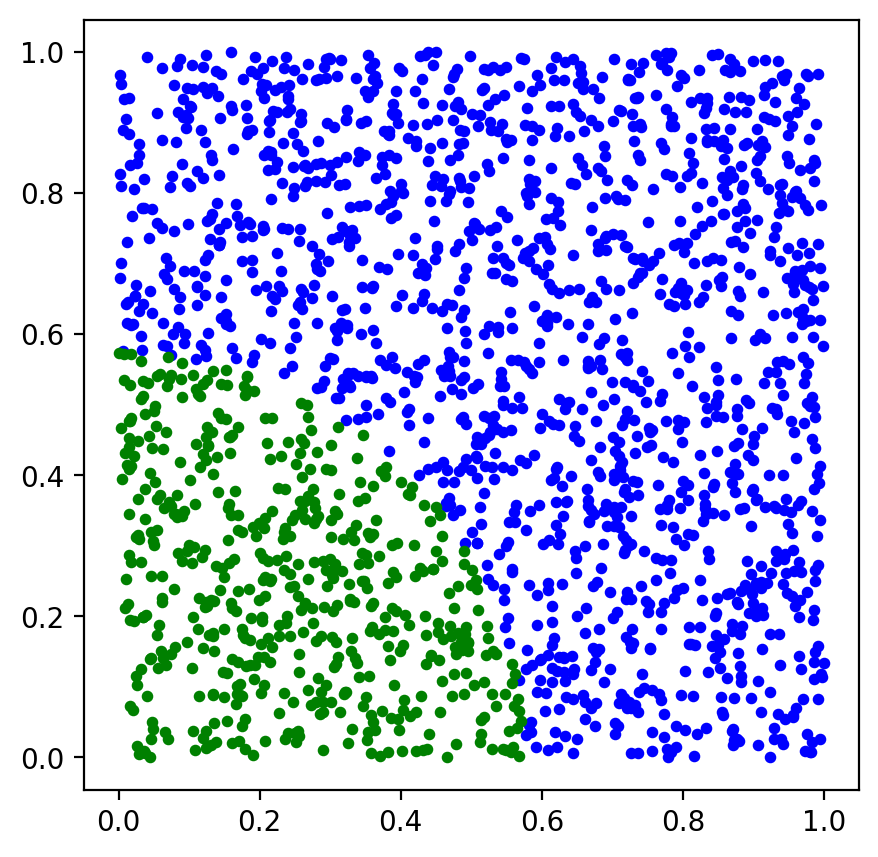

In [64]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN
numpuntosplot=2000
np.random.seed(2025)
train_samples = crea_datos(NUM_PUNTOS_TRAIN)
plot_data(train_samples[0:numpuntosplot])

In [65]:
test_samples = crea_datos(NUM_PUNTOS_TEST)
net = Network ([2, 10, 4, 1])
#net = Network ([2, 3, 1])

nepochs = 20 #round(NUM_PUNTOS_TRAIN/batch_size)
batch_size = 10
learning_rate = 0.5
net.SGD(train_samples , nepochs, batch_size, learning_rate, test_data=test_samples)

Epoch 0 loss [[0.00204256]] Tasa fallos 0.0525
Epoch 1 loss [[0.00014485]] Tasa fallos 0.03
Epoch 2 loss [[0.00392555]] Tasa fallos 0.022
Epoch 3 loss [[0.01734199]] Tasa fallos 0.033
Epoch 4 loss [[0.0002362]] Tasa fallos 0.0165
Epoch 5 loss [[7.30530595e-05]] Tasa fallos 0.036
Epoch 6 loss [[7.95687701e-06]] Tasa fallos 0.015
Epoch 7 loss [[1.31680656e-05]] Tasa fallos 0.018
Epoch 8 loss [[3.30423277e-05]] Tasa fallos 0.0155
Epoch 9 loss [[6.68042092e-08]] Tasa fallos 0.016
Epoch 10 loss [[6.82336479e-08]] Tasa fallos 0.0215
Epoch 11 loss [[5.96559597e-08]] Tasa fallos 0.0225
Epoch 12 loss [[8.02959845e-07]] Tasa fallos 0.023
Epoch 13 loss [[6.28369841e-08]] Tasa fallos 0.023
Epoch 14 loss [[5.85793094e-08]] Tasa fallos 0.0245
Epoch 15 loss [[6.23463296e-08]] Tasa fallos 0.025
Epoch 16 loss [[6.21445757e-08]] Tasa fallos 0.025
Epoch 17 loss [[6.19596568e-08]] Tasa fallos 0.025
Epoch 18 loss [[6.17787274e-08]] Tasa fallos 0.025
Epoch 19 loss [[6.15988506e-08]] Tasa fallos 0.025


In [66]:
aciertos = NUM_PUNTOS_TEST-net.fallos
tasa_test=(aciertos/NUM_PUNTOS_TEST)
print(aciertos,NUM_PUNTOS_TEST)
print("tasa test",tasa_test)

1950.0 2000
tasa test 0.975


In [67]:
fallos, test_results = net.evaluate(test_samples)
npunt = min(numpuntosplot,NUM_PUNTOS_TEST)
labels=1.0*np.array(test_results)[0:npunt]
test_labels = np.array([test_samples[k][2] for k in range(npunt)])
for i in range(npunt):
    if (labels[i] != test_labels[i]):
        labels[i] = 2

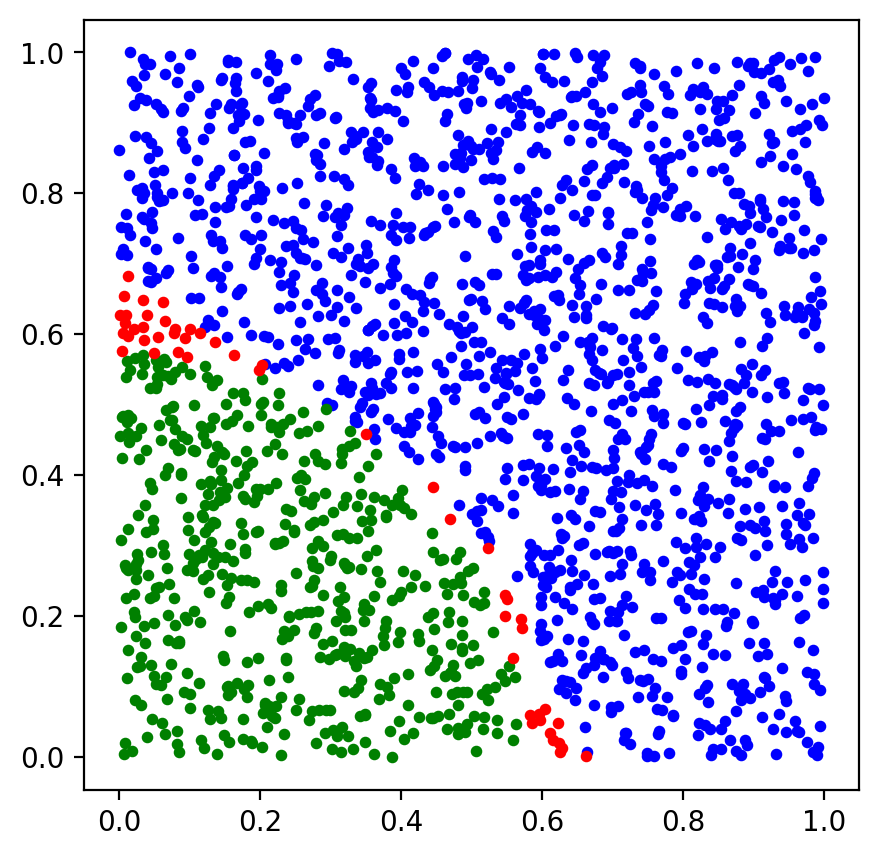

In [68]:
plot_data(test_samples[0:npunt],plabels=labels)